# House Price Prediction - Simple Linear Regression (OLS)

In this notebook, we build a baseline simple linear regression model to predict house prices in King County, Washington using just one feature: **`sqft_living`** (interior living area in square feet).

We use the Ordinary Least Squares (OLS) method through scikit-learn's `LinearRegression`.

### Workflow:
1. Load and explore the data
2. Split into train and test sets (80% train, 20% test)
3. Fit the linear regression model
4. Evaluate performance (MAE, MSE, RMSE, R2)
5. Plot the fitted regression line
6. Test linear regression assumptions (Linearity, Independence, Homoscedasticity, Normality)

## 1. Imports and Setup

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, root_mean_squared_error, r2_score


## 2. Load the Dataset

In [2]:
house_data = pd.read_csv("../data/processed/kc_house_simple_lr.csv")

In [3]:
house_data.head()

,sqft_living,price
0,1180,221900.0
1,2570,538000.0
2,770,180000.0
3,1960,604000.0
4,1680,510000.0


## 3. Train-Test Split

We set aside 20% of the data to test how well our model generalizes to unseen houses.

In [4]:
X = house_data[["sqft_living"]]
X

,sqft_living
0,1180
1,2570
2,770
3,1960
4,1680
...,...
21608,1530
21609,2310
21610,1020
21611,1600


In [5]:
y = house_data["price"]
y

0        221900.0
1        538000.0
2        180000.0
3        604000.0
4        510000.0
           ...   
21608    360000.0
21609    400000.0
21610    402101.0
21611    400000.0
21612    325000.0
Name: price, Length: 21613, dtype: float64

In [6]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

## 4. Train the Model (OLS)

In [7]:
model = LinearRegression()

In [8]:
model.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1,)",[279.55]
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](1,)",['sqft_living']
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,-4.2e+04
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int,1


## 5. Model Parameters

Let's check the learned intercept and slope.

In [9]:
model.intercept_

np.float64(-41999.1860399358)

In [10]:
model.coef_[0]

np.float64(279.5547793152631)

In [19]:
b0 = model.intercept_
b1 = model.coef_[0]

print("Intercept:", b0)
print("Coefficient:", b1)
print(f"Equation: ŷ = {b0:.2f} + {b1:.2f} × sqft_living")

Intercept: -41999.1860399358
Coefficient: 279.5547793152631
Equation: ŷ = -41999.19 + 279.55 × sqft_living


### Interpreting the numbers:
- **Slope (279.55)**: On average, each additional square foot of living area increases the predicted house price by about **$280**.
- **Intercept (-41,999.19)**: The mathematical starting point where living area is 0. A 0 sqft house doesn't exist in reality, so this is just the intercept that fits the line best for real homes.

## 6. Model Evaluation on Test Data

In [11]:
y_pred = model.predict(X_test)

In [12]:
y_pred[:10]

array([ 536679.20714266,  768709.67397433, 1011922.33197861,
       1232770.60763766,  670865.50121399,  436039.48658916,
        710003.17031812,  461199.41672754,  405288.46086449,
        212395.66313695])

In [13]:
y_test.iloc[:10].values

array([ 365000.,  865000., 1038000., 1490000.,  711000.,  211000.,
        790000.,  680000.,  384500.,  605000.])

### Error Metrics and R2 Score

In [14]:
mae = mean_absolute_error(y_test, y_pred)
mae

177867.54034434847

In [15]:
mse = mean_squared_error(y_test, y_pred)
mse

76484977061.77612

In [16]:
rmse = root_mean_squared_error(y_test, y_pred)
rmse

276559.1746114674

In [17]:
ordinay_r2_score = r2_score(y_test, y_pred)
ordinay_r2_score

0.49406905389089006

In [20]:
n = len(y_test)
p = X_test.shape[1]

adjusted_r2_score = 1 - ((1 - ordinay_r2_score) * (n - 1)) / (n - p - 1)
adjusted_r2_score

0.49395196734932345

### What the evaluation metrics tell us:
- **R2 of 0.494**: Living area explains about **49.4%** of the variance in house prices. The remaining 50% depends on location, condition, bathrooms, view, and other factors.
- **MAE (~$178k) vs RMSE (~$277k)**: On average, predictions are off by about $178k. The RMSE is significantly higher because it penalizes big prediction errors heavily, and this dataset contains several multi-million dollar luxury homes.

## 7. Visualizing the Best-Fit Line

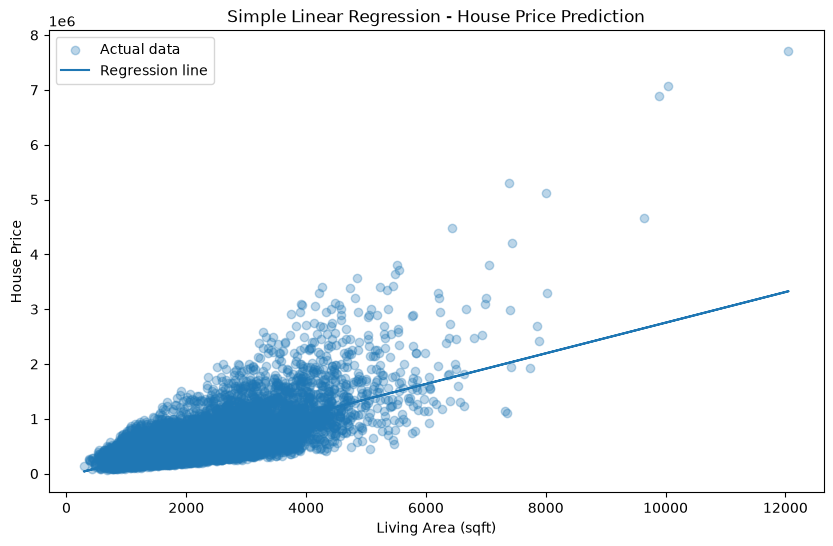

In [18]:
plt.figure(figsize=(10, 6))

plt.scatter(X_train, y_train, alpha=0.3, label="Actual data")

plt.plot(X_train, model.predict(X_train), label="Regression line")

plt.xlabel("Living Area (sqft)")
plt.ylabel("House Price")
plt.title("Simple Linear Regression - House Price Prediction")

plt.legend()
plt.show()

## 8. Checking Linear Regression Assumptions

Before relying on linear regression results, we should check whether the data meets the 4 main assumptions.

In [21]:
residuals = y_test - y_pred
residuals

735     -171679.207143
2830      96290.326026
4106      26077.668021
16218    257229.392362
19964     40134.498786
             ...      
13674     30555.711896
20377    -76140.839422
8805    -353437.146813
10168     18000.932581
2522    -319956.596800
Name: price, Length: 4323, dtype: float64

In [22]:
residuals.describe()

count    4.323000e+03
mean     3.206783e+03
std      2.765726e+05
min     -1.463173e+06
25%     -1.444797e+05
50%     -2.387956e+04
75%      1.081893e+05
max      3.155561e+06
Name: price, dtype: float64

### Assumption 1: Linearity

Is there a straight-line relationship between living area and price?

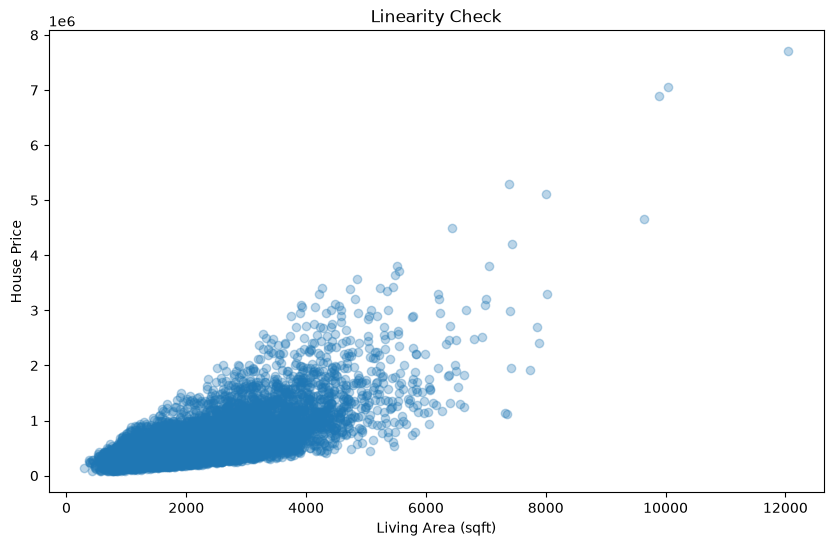

In [25]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.scatter(X_train, y_train, alpha=0.3)

plt.xlabel("Living Area (sqft)")
plt.ylabel("House Price")
plt.title("Linearity Check")

plt.show()

> **Result**: The scatter plot shows a steady upward trend. As square footage increases, price increases in an approximately linear fashion. So linearity holds.

### Assumption 2: Independence

Are the residuals independent, or do they follow a time or sequence pattern?

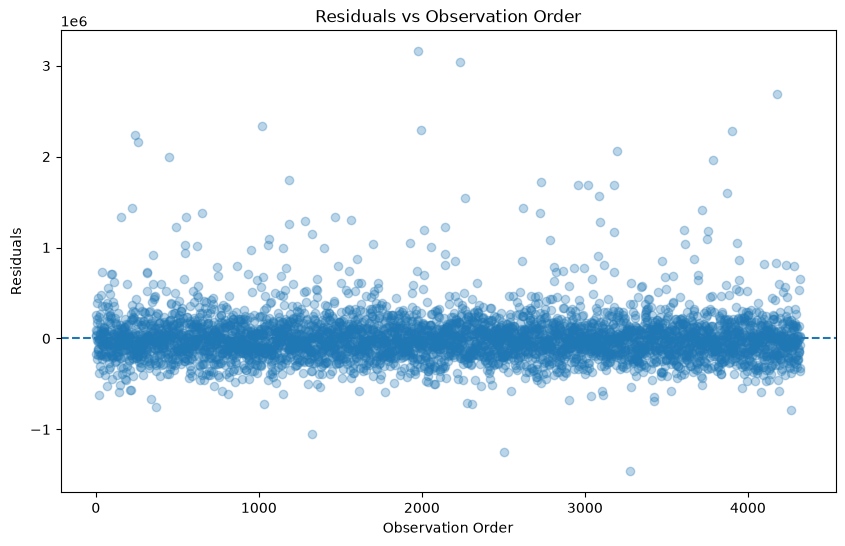

In [27]:
plt.figure(figsize=(10, 6))

plt.scatter(range(len(residuals)), residuals, alpha=0.3)

plt.axhline(y=0, linestyle="--")

plt.xlabel("Observation Order")
plt.ylabel("Residuals")
plt.title("Residuals vs Observation Order")

plt.show()

> **Result**: The residuals are randomly scattered around zero with no visible trend or clustering. Independence holds.

### Assumption 3: Homoscedasticity

Is the spread of residuals constant across all price levels?

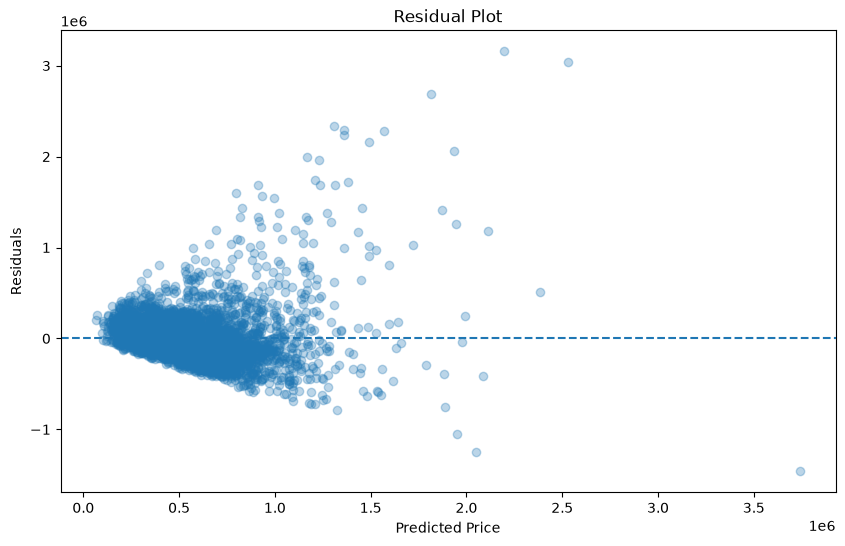

In [23]:
plt.figure(figsize=(10, 6))

plt.scatter(y_pred, residuals, alpha=0.3)

plt.axhline(y=0, linestyle="--")

plt.xlabel("Predicted Price")
plt.ylabel("Residuals")
plt.title("Residual Plot")

plt.show()

> **Result**: The residual spread fans out as predicted price gets higher. This means the model has higher variance and error for expensive houses than for cheaper ones. Homoscedasticity is violated.

### Assumption 4: Normality of Residuals

Are the errors normally distributed around zero?

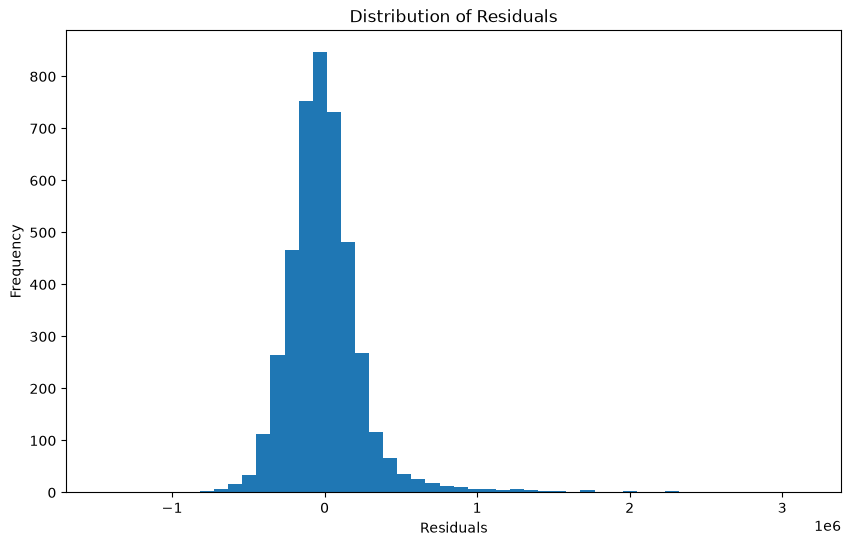

In [24]:
plt.figure(figsize=(10, 6))

plt.hist(residuals, bins=50)

plt.xlabel("Residuals")
plt.ylabel("Frequency")
plt.title("Distribution of Residuals")

plt.show()

> **Result**: While the peak is around zero, there is a long tail to the right. This skewness comes from high-priced luxury houses that the simple model underpredicts. Normality is not fully satisfied.

## 9. Summary of Findings

| Assumption | Status | What we observed |
| :--- | :--- | :--- |
| **Linearity** | Passed | Clear positive linear relationship between living area and price |
| **Independence** | Passed | Residuals are randomly scattered across observations |
| **Homoscedasticity** | Violated | Error spread widens for higher-priced homes |
| **Normality** | Violated | Right-skewed error distribution due to luxury house outliers |

In the next notebook, we explore **Gradient Descent** as an alternative way to train this same linear model.